# Workshop 6: CNN for image recognition

**Real-life problem:** A second-hand marketplace for DJ gear gets a photo with every listing. Could a model put each listing in the right section (record deck, mixer or digital deck) from the photo alone, when all you have is about 100 labelled photos?

**My twist:** Port the lecturer's CIFAR-10 CNN from the PDF, then train the same network on 93 photos of DJ gear from Wikimedia Commons in three classes, and compare it with a network pretrained on ImageNet (MobileNetV2) used as a feature extractor. Five folds so every photo is tested once, a confusion matrix, the five most confident mistakes, and what the model says about photos that aren't DJ gear at all.

**Done when:** Test accuracy, a confusion matrix, and 5 misclassified images with a guess at why.

*Part A is the lecturer's code, ported from the workshop PDF (`_baseline/pdf/`, not published). Part B is my twist.*

## Part A: a CNN on CIFAR-10 (the lecturer's code, ported from the PDF)

The PDF's code, step by step, on 60,000 small photos in 10 classes. Changes, all small:
- **Training prints one line per epoch** (`verbose=2`) instead of a progress bar, and a fixed seed makes the run repeatable.
- **The model is saved in Keras 3's own `.keras` format.** The PDF's `.h5` is now a legacy format. Both are git-ignored.
- **"Your own image" is a turntable**, one of Part B's photos, instead of the lecturer's cat, which isn't included. It is resized with Keras's `load_img`, because scikit-image isn't installed here.

Training takes about 10 minutes on a laptop CPU (M1 Max).

In [1]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'     # hide TensorFlow start-up messages
warnings.filterwarnings('ignore')            # Keras 3 warnings print file paths from your computer

from keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()   # downloads once (about 170 MB), then cached in ~/.keras
print('x_train shape:', x_train.shape)
print('y_train shape:', y_train.shape)

x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)


In [2]:
print(x_train[0])

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]


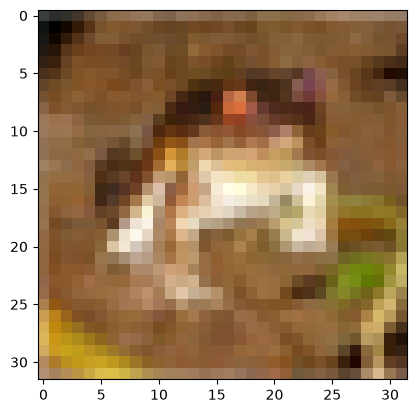

The label is: [6]


In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
img = plt.imshow(x_train[0])
plt.show()
print('The label is:', y_train[0])

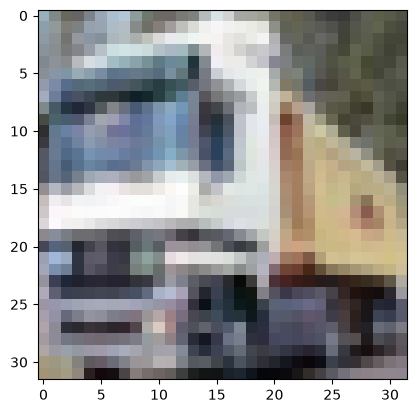

The label is: [9]


In [4]:
img = plt.imshow(x_train[1])
plt.show()
print('The label is:', y_train[1])

In [5]:
import keras
y_train_one_hot = keras.utils.to_categorical(y_train, 10)
y_test_one_hot = keras.utils.to_categorical(y_test, 10)
print('The one hot label is:', y_train_one_hot[1])

The one hot label is: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [6]:
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train / 255
x_test = x_test / 255
print(x_train[0][0][:3], '... (first three pixels of the first row, now between 0 and 1)')

[[0.23137255 0.24313726 0.24705882]
 [0.16862746 0.18039216 0.1764706 ]
 [0.19607843 0.1882353  0.16862746]] ... (first three pixels of the first row, now between 0 and 1)


In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D

keras.utils.set_random_seed(0)   # added: the same result on every run
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32,32,3)))
model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,168,362 (8.27 MB)

 Trainable params: 2,168,362 (8.27 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
hist = model.fit(x_train, y_train_one_hot, batch_size=32, epochs=20, validation_split=0.2, verbose=2)

Epoch 1/20


1250/1250 - 27s - 22ms/step - accuracy: 0.4361 - loss: 1.5453 - val_accuracy: 0.6000 - val_loss: 1.1336


Epoch 2/20


1250/1250 - 25s - 20ms/step - accuracy: 0.5902 - loss: 1.1397 - val_accuracy: 0.6556 - val_loss: 0.9727


Epoch 3/20


...

1250/1250 - 26s - 21ms/step - accuracy: 0.8460 - loss: 0.4394 - val_accuracy: 0.7702 - val_loss: 0.7166


Epoch 19/20


1250/1250 - 27s - 21ms/step - accuracy: 0.8501 - loss: 0.4244 - val_accuracy: 0.7747 - val_loss: 0.7250


Epoch 20/20


1250/1250 - 24s - 19ms/step - accuracy: 0.8555 - loss: 0.4100 - val_accuracy: 0.7678 - val_loss: 0.7761


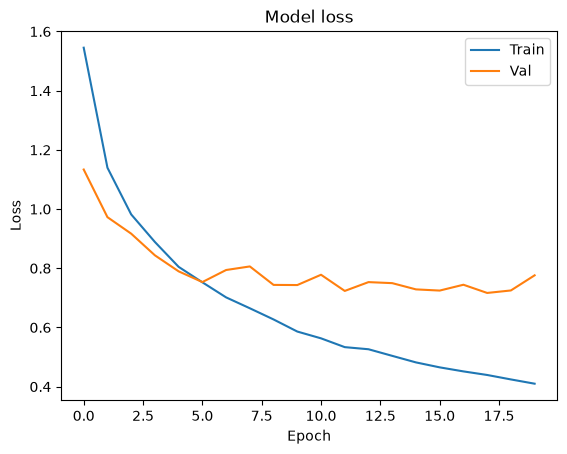

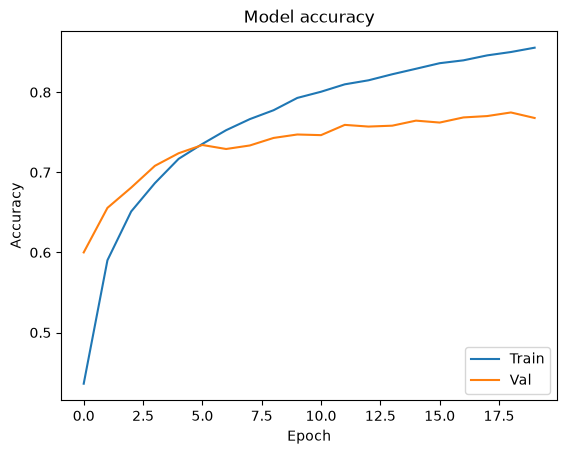

In [9]:
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper right')
plt.show()

plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower right')
plt.show()

In [10]:
print('Test accuracy:', model.evaluate(x_test, y_test_one_hot, verbose=0)[1])

Test accuracy: 0.7608000040054321


In [11]:
model.save('my_cifar10_model.keras')
# to load it again later:
# from keras.models import load_model
# model = load_model('my_cifar10_model.keras')

### Testing with your own image
The lecturer's cat isn't included, so the "own image" is a Technics SL-1200 turntable from Part B's photos. CIFAR-10 has no class for it, which is the point: the model can only answer with the ten things it knows.

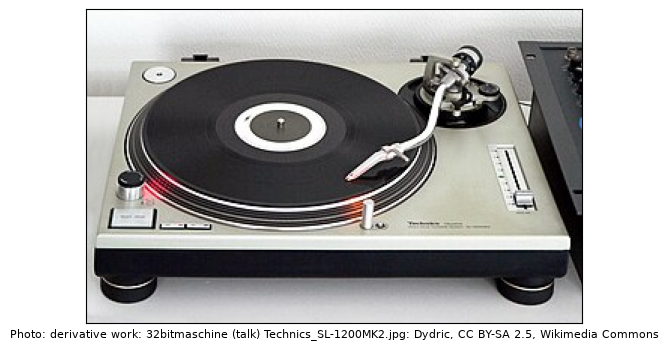

In [12]:
import csv, urllib.request
credits = {r['file']: r for r in csv.DictReader(open('dj_gear_photos.csv'))}
photo = credits['record_deck/03136f_Technics_SL-1200MK2-2.jpg']
path = os.path.join('dj_gear_photos', photo['file'])
if not os.path.exists(path):   # the photos aren't in the repo: fetch this one from Wikimedia Commons
    os.makedirs(os.path.dirname(path), exist_ok=True)
    request = urllib.request.Request(photo['thumb_url'], headers={'User-Agent': 'AIStudioWorkshops/1.0 (coursework)'})
    with urllib.request.urlopen(request, timeout=30) as r, open(path, 'wb') as f:
        f.write(r.read())

my_image = plt.imread(path)
img = plt.imshow(my_image)
plt.xticks([]); plt.yticks([])
plt.xlabel(f"Photo: {' '.join(photo['author'].split())}, {photo['licence']}, Wikimedia Commons", fontsize=8)
plt.show()

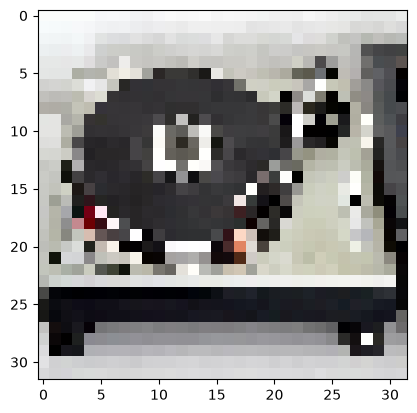

In [13]:
my_image_resized = keras.utils.img_to_array(keras.utils.load_img(path, target_size=(32, 32))) / 255
img = plt.imshow(my_image_resized)
plt.show()

In [14]:
import numpy as np
probabilities = model.predict(np.array( [my_image_resized,] ), verbose=0)
number_to_class = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
index = np.argsort(probabilities[0,:])
print("Most likely class:", number_to_class[index[9]], "-- Probability:", probabilities[0,index[9]])
print("Second most likely class:", number_to_class[index[8]], "-- Probability:", probabilities[0,index[8]])
print("Third most likely class:", number_to_class[index[7]], "-- Probability:", probabilities[0,index[7]])
print("Fourth most likely class:", number_to_class[index[6]], "-- Probability:", probabilities[0,index[6]])
print("Fifth most likely class:", number_to_class[index[5]], "-- Probability:", probabilities[0,index[5]])

Most likely class: truck -- Probability: 0.97825235
Second most likely class: ship -- Probability: 0.021746675
Third most likely class: automobile -- Probability: 9.000958e-07
Fourth most likely class: airplane -- Probability: 1.3525013e-09
Fifth most likely class: horse -- Probability: 1.0849515e-12


- **Test accuracy: 76.1%** on the 10,000 test photos, against 10% for a blind guess.
- **More epochs buy little after about epoch 6.** The training loss keeps falling, but the validation loss stops improving and wobbles between 0.72 and 0.81. Validation accuracy only creeps from 73% to 77%, while training accuracy reaches 86%. The gap means the model is starting to memorise the training photos.
- **The turntable comes out as a truck (98% sure), then a ship.** Shrunk to 32 × 32 it is a grey box with a dark circle on top, and the model must answer with one of its ten classes, so it picks the nearest boxy thing it knows. That sets up Part B: what does it take to teach a CNN a new kind of object?

---
## Part B: real life: which section does this listing belong in?

**Problem:** on a second-hand marketplace for DJ gear, sellers pick a category by hand, and a wrong or missing one hides the listing from buyers who filter by it. A model that suggests the category from the photo would catch most of that. The catch: nobody hands you 50,000 labelled photos. **Can the lecturer's CNN learn three kinds of DJ gear from about 100 photos, and if not, what can?**

**Data:** 101 photos from Wikimedia Commons (thumbnails about 330 pixels wide), found through its categories for turntables, DJ mixers, CDJs and DJ controllers, and checked by eye:
- **record deck** (22): turntables for vinyl.
- **mixer** (24): DJ mixers on their own.
- **digital deck** (47): CDJ media players and all-in-one DJ controllers.
- **8 rejected:** things the category search returned that aren't DJ gear (a railway turntable, a plane registered CC-CDJ, a toy DJ Hero deck, a map). They are kept aside for section 4.

The licences are CC BY, CC BY-SA, CC0 or public domain. Every photo shown below carries its author and licence, and `dj_gear_photos.csv` has the full credits and links. The photos themselves aren't in the repo: the first cell downloads any that are missing.

**Fair testing:** with 93 photos, a 20% test set is only 19 photos, and one lucky split can move accuracy by 10 points. Instead the photos are split into five folds, and each model is trained five times, each time on four folds and tested on the fifth. Every photo is tested exactly once, by a model that never saw it. Near-copies (crops of one photo, or several shots from one session) stay in the same fold.

In [15]:
import os, re, csv, time, warnings, textwrap, urllib.request
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
tf.get_logger().setLevel('ERROR')
%config InlineBackend.figure_formats = ['jpeg']   # photo grids as JPEG keep the notebook small (PNG made it 5 MB)

CLASSES = ['record_deck', 'dj_mixer', 'digital_deck']
NAMES = {'record_deck': 'record deck', 'dj_mixer': 'mixer', 'digital_deck': 'digital deck'}
photos = pd.read_csv('dj_gear_photos.csv')

def fetch(row):
    # the photos aren't in the repo (licences): download any that are missing from Wikimedia Commons
    path = os.path.join('dj_gear_photos', row.file)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        request = urllib.request.Request(row.thumb_url, headers={'User-Agent': 'AIStudioWorkshops/1.0 (coursework)'})
        with urllib.request.urlopen(request, timeout=30) as r, open(path, 'wb') as f:
            f.write(r.read())
    return path

def load(paths, size):
    return np.stack([np.asarray(Image.open(p).convert('RGB').resize((size, size)), dtype='float32') for p in paths])

def short(text, width=40):
    text = re.sub(r'[^\u0000-ɏ]+', ' ', str(text))          # the plot font has no Chinese or Japanese characters
    return textwrap.shorten(' '.join(text.split()), width, placeholder='…')

def credit(row):
    return f'{short(row.author)} · {row.licence}'

photos['path'] = [fetch(row) for row in photos.itertuples()]
gear = photos[photos.label != 'rejected_example'].reset_index(drop=True)
others = photos[photos.label == 'rejected_example'].reset_index(drop=True)
y = gear.label.map(CLASSES.index).to_numpy()

# Near-copies (found by an image-similarity check, then reading titles and credits): crops and edits of one
# photo, and several shots from one session by one photographer. Each set stays in a single fold.
SAME_SHOOT = ['Printemps de Bourges 2019-15', 'Numark Mixdeck-47', 'EZToller5 EZ2DJ']
groups = [next((key for key in SAME_SHOOT if key in title), title) for title in gear.title]
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(gear, y, groups))

print(f'{len(gear)} photos of DJ gear, {len(others)} that are not; photos in each test fold: {[len(test) for _, test in folds]}')
pd.crosstab(gear.label.map(NAMES).rename('class'), gear.commons_source.str.replace('_', ' ').rename('Commons category'),
            margins=True, margins_name='total')

93 photos of DJ gear, 8 that are not; photos in each test fold: [19, 19, 19, 18, 18]


Commons category,cdj media player,dj controller,dj mixer,turntable,total
class,,,,,
digital deck,9,38,0,0,47
mixer,0,0,24,0,24
record deck,0,0,0,22,22
total,9,38,24,22,93


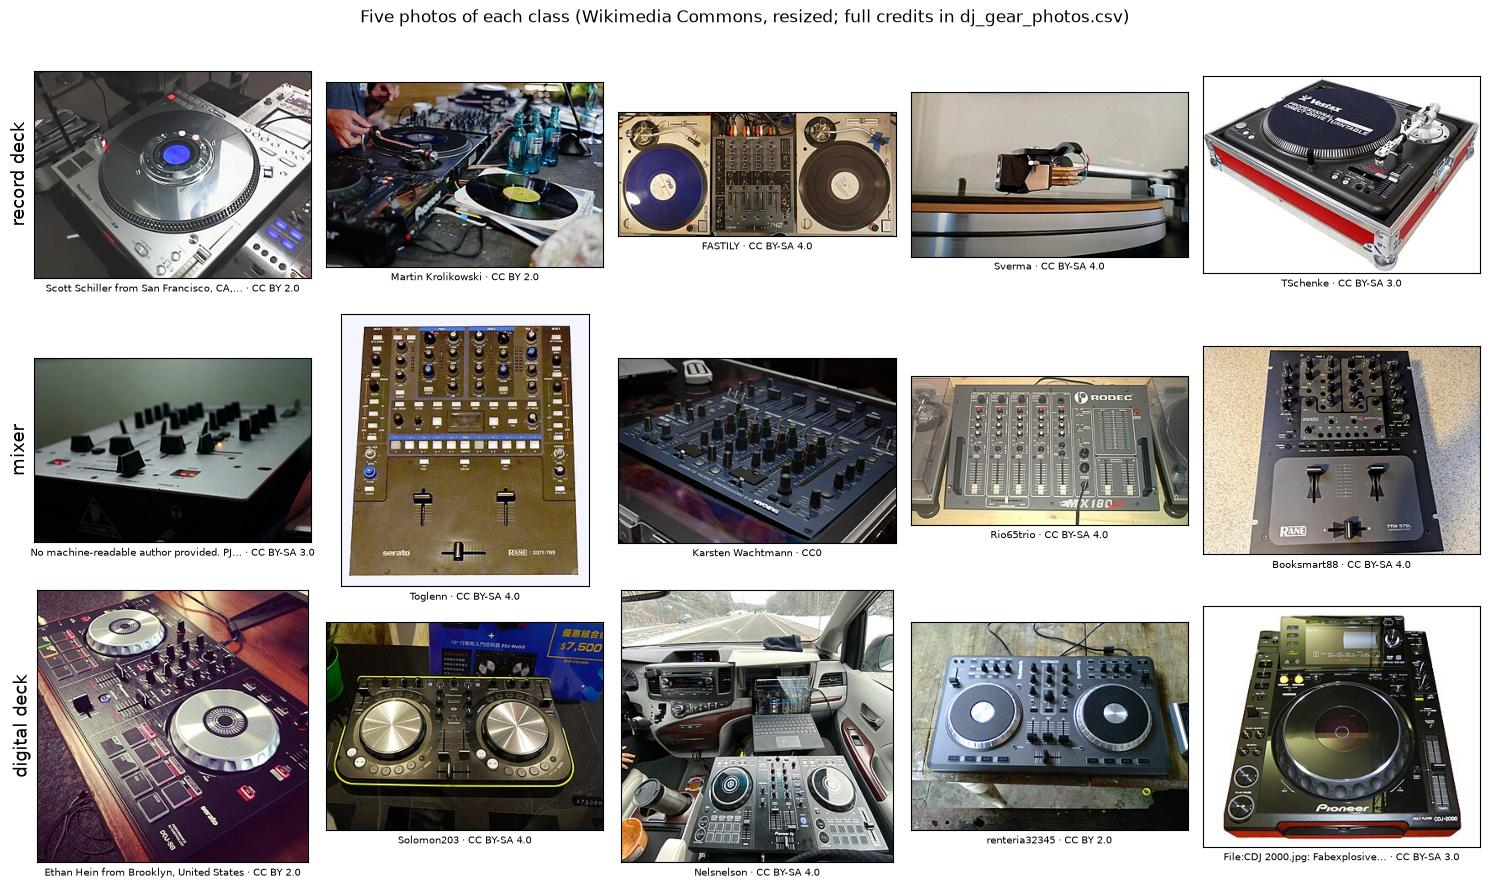

In [16]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax_row, label in zip(axes, CLASSES):
    for ax, row in zip(ax_row, gear[gear.label == label].sample(5, random_state=1).itertuples()):
        ax.imshow(Image.open(row.path)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(credit(row), fontsize=7)
    ax_row[0].set_ylabel(NAMES[label], fontsize=13)
fig.suptitle('Five photos of each class (Wikimedia Commons, resized; full credits in dj_gear_photos.csv)')
plt.tight_layout(); plt.show()

### 1. Which model?
Four ways to label a photo, all tested on the same five folds:
1. **Always guess "digital deck"**, the largest class. Any model has to beat this.
2. **The lecturer's CNN, trained from scratch:** Part A's network unchanged except for 64 × 64 photos instead of 32 × 32 (so a platter and a jog wheel still look different) and 3 outputs instead of 10. 20 epochs, as in the PDF.
3. **The same CNN with augmentation:** random flips, small turns and zooms, so each epoch sees slightly different photos. This is the usual fix when photos are few.
4. **A pretrained network (transfer learning):** MobileNetV2 is a CNN that Google trained on 1.2 million ImageNet photos. It turns each photo into 1,280 numbers describing what it sees, and a logistic regression then learns which numbers mean which kind of gear. Only the logistic regression is trained here.

In [17]:
results, proba = {}, {}

def evaluate(name, fit_predict, n_trained, extra_seconds=0):
    # train on four folds, test on the fifth, five times: every photo is tested once, by a model that never saw it
    start = time.time()
    p = np.zeros((len(y), 3))
    for k, (train, test) in enumerate(folds):
        p[test] = fit_predict(train, test, k)
    proba[name] = p
    pred = p.argmax(1)
    fold_acc = [(pred[test] == y[test]).mean() * 100 for _, test in folds]
    results[name] = {'accuracy (%)': (pred == y).mean() * 100, 'worst fold (%)': min(fold_acc), 'best fold (%)': max(fold_acc),
                     **{f'{NAMES[c]}s found (%)': (pred[y == i] == i).mean() * 100 for i, c in enumerate(CLASSES)},
                     'training time (s)': time.time() - start + extra_seconds, 'parameters trained': n_trained}

# 1) always guess the most common class in the training folds
def always_biggest(train, test, k):
    p = np.zeros((len(test), 3)); p[:, np.bincount(y[train]).argmax()] = 1
    return p
evaluate('always guess "digital deck"', always_biggest, 0)

# 2) and 3) the lecturer's CNN, without and with augmentation
X64 = load(gear.path, 64) / 255

def lecturer_cnn(augment=False):
    model = keras.Sequential([keras.Input((64, 64, 3))])
    if augment:
        model.add(layers.RandomFlip('horizontal')); model.add(layers.RandomRotation(0.08)); model.add(layers.RandomZoom(0.2))
    for depth in (32, 64):
        model.add(layers.Conv2D(depth, (3, 3), activation='relu', padding='same'))
        model.add(layers.Conv2D(depth, (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))
        model.add(layers.Dropout(0.25))
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(3, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

def train_cnn(augment):
    def fit_predict(train, test, k):
        keras.utils.set_random_seed(k)
        model = lecturer_cnn(augment)
        model.fit(X64[train], keras.utils.to_categorical(y[train], 3), batch_size=32, epochs=20, verbose=0)
        return model.predict(X64[test], verbose=0)
    return fit_predict

evaluate("lecturer's CNN, from scratch", train_cnn(False), lecturer_cnn().count_params())
evaluate("lecturer's CNN + augmentation", train_cnn(True), lecturer_cnn(True).count_params())

# 4) pretrained MobileNetV2 turns each photo into 1,280 numbers; a logistic regression learns the classes
start = time.time()
base = keras.applications.MobileNetV2(include_top=False, weights='imagenet', pooling='avg', input_shape=(224, 224, 3))   # downloads once (about 9 MB)
features = base.predict(keras.applications.mobilenet_v2.preprocess_input(load(gear.path, 224)), verbose=0)
feature_seconds = time.time() - start

def pretrained(train, test, k):
    return LogisticRegression(max_iter=5000).fit(features[train], y[train]).predict_proba(features[test])
evaluate('pretrained MobileNetV2 + logistic regression', pretrained, features.shape[1] * 3 + 3, feature_seconds)

table = pd.DataFrame(results).T
table['training time (s)'] = table['training time (s)'].round(0).astype(int)
table['parameters trained'] = table['parameters trained'].astype(int)
table.round(1)

,accuracy (%),worst fold (%),best fold (%),record decks found (%),mixers found (%),digital decks found (%),training time (s),parameters trained
"always guess ""digital deck""",50.5,47.4,52.6,0.0,0.0,100.0,0,0
"lecturer's CNN, from scratch",47.3,36.8,57.9,9.1,41.7,68.1,25,8456227
lecturer's CNN + augmentation,45.2,36.8,61.1,9.1,16.7,76.6,26,8456227
pretrained MobileNetV2 + logistic regression,82.8,72.2,89.5,72.7,83.3,87.2,2,3843


- **The lecturer's CNN does worse than guessing.** Trained from scratch, it gets 47% of photos right, below the 50.5% you'd get by always saying "digital deck", and it finds only 2 of the 22 record decks. Augmentation doesn't rescue it (45%). Each time, it has about 74 training photos and 8.5 million numbers to learn, far more than the photos can pin down, so it memorises the photos instead of learning the gear. A trial run with 50 epochs (not shown) was no better.
- **The pretrained network gets 83% right** (77 of 93 photos), between 72% and 89% depending on the fold. It finds 73% of record decks, 83% of mixers and 87% of digital decks.
- **And it is far cheaper:** about 2 seconds, including turning the photos into numbers, against about 25 seconds. It trains 3,843 numbers instead of 8.5 million. The hard part, recognising edges, circles, knobs and faders, was learned once, by Google, from 1.2 million photos.
- **How precise is 83%?** With 93 photos, roughly ±8 points either way. It is far better than guessing, but a point or two means nothing.

### 2. Where does each model go wrong?
Every photo's test result, pooled over the five folds: rows are what the photo is, columns what the model said.

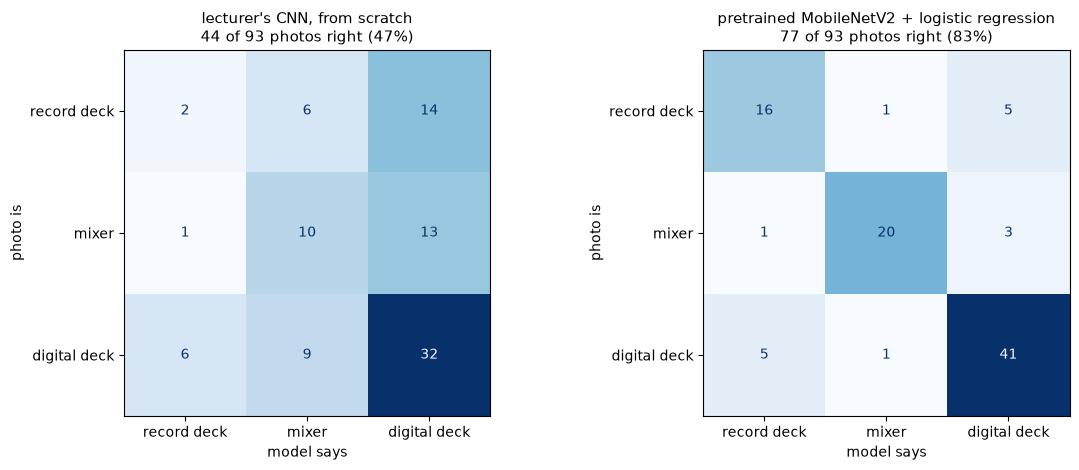

In [18]:
best = 'pretrained MobileNetV2 + logistic regression'
labels = [NAMES[c] for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, name in zip(axes, ["lecturer's CNN, from scratch", best]):
    pred = proba[name].argmax(1)
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=labels).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\n{(pred == y).sum()} of {len(y)} photos right ({(pred == y).mean():.0%})', fontsize=11)
    ax.set_xlabel('model says'); ax.set_ylabel('photo is')
plt.tight_layout(); plt.show()

- **The lecturer's CNN mostly says "digital deck"** (59 of 93 photos), the biggest class, and gets record decks almost entirely wrong (2 of 22 right).
- **The pretrained model mostly confuses record decks with digital decks** (10 of its 16 mistakes): 5 record decks called digital decks, and 5 digital decks called record decks. Both have a big round thing on top, a platter or a jog wheel. Mixers are rarely confused with anything (20 of 24 right).

### 3. The five most confident mistakes
Where the best model was surest, and wrong. Reading these is the quickest way to see what it doesn't understand.

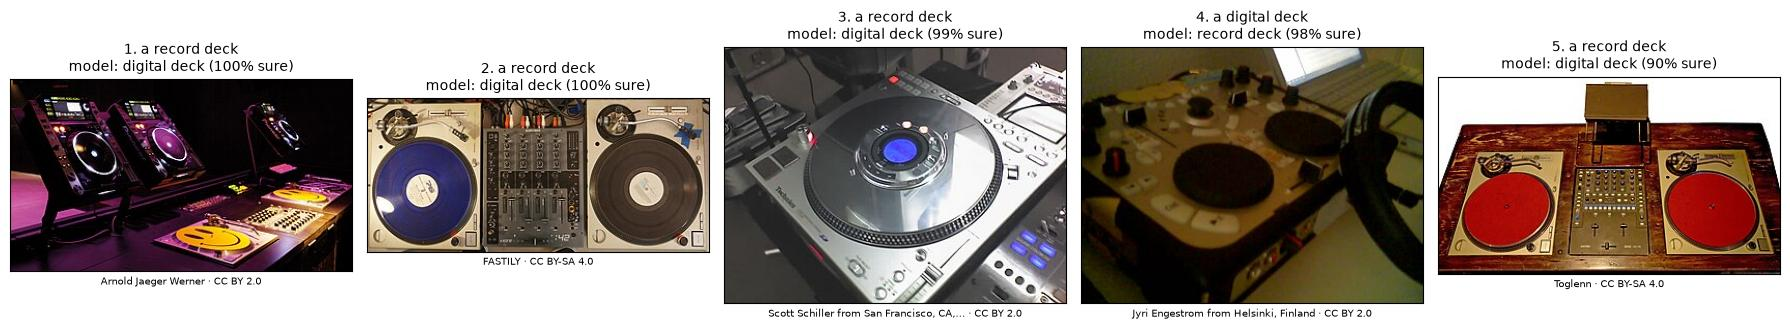

All 16 mistakes, surest first:


,photo,is a,model says,sure (%)
1,Three CDJs and two SL-1210 at Bob Beaman Nightclub Munich,record deck,digital deck,100
2,Technics 1200 and Xone 42 1 2016-06-17,record deck,digital deck,100
3,Technics SL-DZ1200 Digital DJ Turntable,record deck,digital deck,99
4,Hercules DJ Control Double Deck,digital deck,record deck,98
5,"Two Technics SL-1200 MkII and a Serato DJ Mixer, Vintage DJ Station 2019 by Glenn Fran...",record deck,digital deck,90
6,"Realistic stereo mixing console - Sir Theo, Belgaum, India (2011-11-23 08.39.23 by jul...",mixer,digital deck,88
7,Video Mixer Edirol V-4,mixer,digital deck,66
8,"Little Game Park Tracker (LGPT, aka Piggy Tracker) running on Dingoo, along with Rane ...",mixer,record deck,65
9,"Deejaying - Hamburger Börs, 2015-03-14 (by Hannu Makarainen)",digital deck,record deck,60
10,Turntable Vestax-PDX3000,record deck,digital deck,59


In [19]:
pred, sure = proba[best].argmax(1), proba[best].max(1)
wrong = np.where(pred != y)[0]
top = wrong[np.argsort(-sure[wrong])]

fig, axes = plt.subplots(1, 5, figsize=(18, 4.4))
for n, (ax, i) in enumerate(zip(axes, top[:5]), start=1):
    row = gear.iloc[i]
    ax.imshow(Image.open(row.path)); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{n}. a {NAMES[CLASSES[y[i]]]}\nmodel: {NAMES[CLASSES[pred[i]]]} ({sure[i]:.0%} sure)', fontsize=10)
    ax.set_xlabel(credit(row), fontsize=7)
plt.tight_layout(); plt.show()

pd.set_option('display.max_colwidth', 90)
print(f'All {len(wrong)} mistakes, surest first:')
pd.DataFrame({'photo': gear.title[top].str.replace('File:', '', regex=False).str.replace(r'\.\w+$', '', regex=True),
              'is a': [NAMES[CLASSES[c]] for c in y[top]], 'model says': [NAMES[CLASSES[c]] for c in pred[top]],
              'sure (%)': (sure[top] * 100).round(0).astype(int)}).reset_index(drop=True).rename(lambda i: i + 1)

**My reading of the five** (numbers as in the pictures):
1. **The label is arguable, not the model.** The photo is filed under turntables, but three CDJs fill most of it and the two turntables sit at the front right. A person might have said "digital deck" too.
2. **and 5. A whole setup seen from above:** two turntables either side of a mixer. That is exactly the shape of an all-in-one controller, two round wheels either side of a mixer section, and controllers are most of the digital-deck class. The model learned "two circles with faders between them" means controller.
3. **The label is wrong, not the model.** The Technics SL-DZ1200 sits in Commons' turntable category, but it is a digital deck: it plays CDs and SD cards and only looks like a turntable. The model got it right.
4. **A dim, yellow close-up** of a small controller whose two big jog wheels look like platters. With bad light and an odd angle, there is little else to go on.

**The pattern:** three of the five "mistakes" come from the data, not the model: photos showing more than one kind of gear, and a wrong label. A marketplace has the same problem, because bundles ("two decks and a mixer") are common listings. The categories need a "complete setup" option, or the model needs to say which items it sees instead of picking one.

### 4. Photos that aren't DJ gear at all
A marketplace will also get blurry shots, boxes, cables and things that aren't DJ gear. The model has only three answers, so it gives one of them every time. Here is the best model, now trained on all 93 photos, on the 8 photos rejected while building the dataset. Below that is what a "only auto-tag when sure" rule would do.

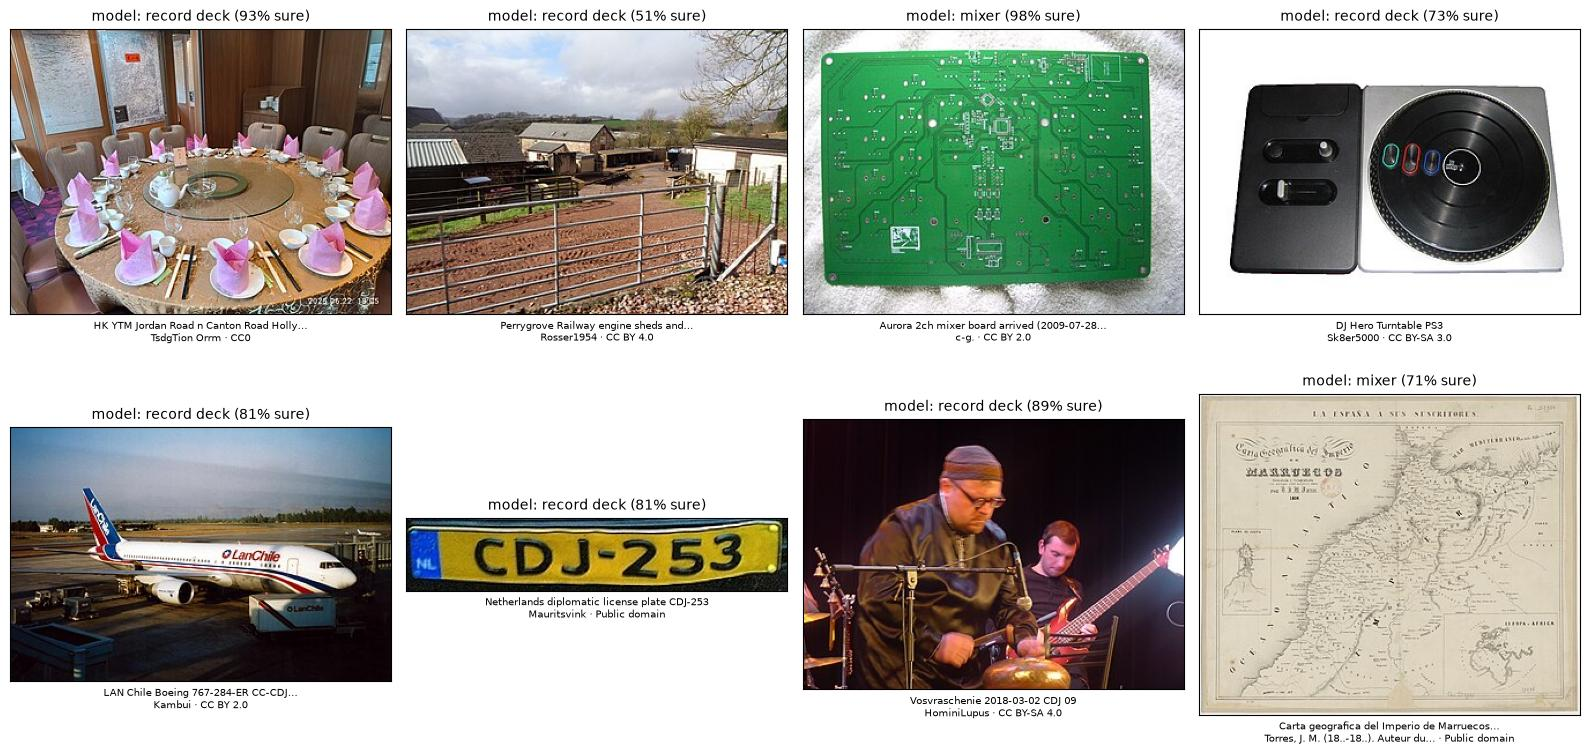

,auto-tag when the model is at least,gear photos auto-tagged (%),"of those, tagged right (%)",left for the seller to choose (%),non-gear photos auto-tagged (of 8)
0,always,100.0,82.8,0.0,8
1,50% sure,96.8,85.6,3.2,8
2,70% sure,84.9,92.4,15.1,7
3,90% sure,73.1,94.1,26.9,2


In [20]:
final = LogisticRegression(max_iter=5000).fit(features, y)
p_other = final.predict_proba(base.predict(keras.applications.mobilenet_v2.preprocess_input(load(others.path, 224)), verbose=0))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row, p in zip(axes.flat, others.itertuples(), p_other):
    ax.imshow(Image.open(row.path)); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'model: {NAMES[CLASSES[p.argmax()]]} ({p.max():.0%} sure)', fontsize=10)
    ax.set_xlabel(f"{short(re.sub(r'^File:|\.\w+$', '', row.title), 44)}\n{credit(row)}", fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for bar in (0, 0.5, 0.7, 0.9):
    auto = sure >= bar
    rows.append({'auto-tag when the model is at least': f'{bar:.0%} sure' if bar else 'always',
                 'gear photos auto-tagged (%)': auto.mean() * 100,
                 'of those, tagged right (%)': (pred[auto] == y[auto]).mean() * 100,
                 'left for the seller to choose (%)': (~auto).mean() * 100,
                 'non-gear photos auto-tagged (of 8)': int((p_other.max(1) >= bar).sum())})
pd.DataFrame(rows).round(1)

- **The model is confidently wrong about things that aren't DJ gear.** A round banquet table is a record deck (93% sure), a bare circuit board a mixer (98%) and a map a mixer (71%): round things become record decks, and rows of small parts become mixers. Even a plane and a licence plate get 81%.
- **So its confidence can't screen out junk photos.** At a 90% bar, 2 of the 8 still get auto-tagged, and they are the two it is surest about.
- **On real DJ gear, a bar does help.** Auto-tag only when the model is at least 70% sure, and 85% of photos get a tag, 92% of them right; the seller picks for the other 15%. At 90%, 73% get a tag, 94% of them right.
- **The fix for junk is data, not a threshold:** a fourth class, "not DJ gear", trained on photos like these (boxes, cables, rooms, people).

### Verdict, and what I'd tell a marketplace team
**Don't train a CNN from scratch on 100 photos: borrow one.** The lecturer's network did worse than always guessing "digital deck" (47% against 50.5%). A network pretrained on ImageNet got 83% in about 2 seconds, training only a logistic regression on top. That fits workshops 5 and 11: a big model pays off only with lots of data, and here the data is borrowed.

**How a marketplace would use it:** suggest a category when the model is at least 70% sure (85% of listings, 92% right) and leave the rest to the seller. The seller confirms or changes each suggestion, and that produces labelled photos to retrain on. Before launch it needs a "not DJ gear" class, because the model can't refuse, and a "complete setup" class, because bundle photos confuse it.

**Caveats:** 93 photos, so every number is rough (about ±8 points). These are Wikimedia Commons photos, often well-lit product shots, not phone photos of real listings. The labels come from Commons categories, and at least one is wrong (the SL-DZ1200). One random split into five folds. No tuning: fine-tuning MobileNetV2's last layers might add a few points.